<a href="https://colab.research.google.com/github/valeencamargo14/TP-Labo-/blob/Tincho/TP_Labo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **3.1. Carga y exploración inicial**

### 3.1.a) Carga de datos y librerías

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los datasets
df_posiciones = pd.read_csv('/content/premier_league_posiciones_2005_2026.csv')
df_gastos = pd.read_csv('/content/premier_league_gastos_2005_2026.csv')

# Mostrar las primeras filas de cada DataFrame
print("--- Posiciones ---")
print(df_posiciones.head(10))
print(df_posiciones.tail(10))

print("\n--- Gastos ---")
print(df_gastos.head(10))
print(df_gastos.tail(10))

--- Posiciones ---
  temporada                    club  posicion  puntos  partidos  ganados  \
0   2025-26              Arsenal FC         1      85        38       26   
1   2025-26         Manchester City         2      78        38       23   
2   2025-26       Manchester United         3      71        38       20   
3   2025-26             Aston Villa         4      65        38       19   
4   2025-26            Liverpool FC         5      60        38       17   
5   2025-26         AFC Bournemouth         6      57        38       13   
6   2025-26          Sunderland AFC         7      54        38       14   
7   2025-26  Brighton & Hove Albion         8      53        38       14   
8   2025-26            Brentford FC         9      53        38       14   
9   2025-26              Chelsea FC        10      52        38       14   

   empatados  perdidos  goles_favor  goles_contra  dif_goles  
0          7         5           71            27         44  
1          9      

### 3.1.a) Carga de datos y librerías
**Qué se hace:** Importamos las librerías `pandas`, `matplotlib` y `seaborn`, y cargamos los dos archivos CSV en DataFrames. Mostramos las primeras y últimas filas.
**Por qué:** `pandas` es el motor que nos permite estructurar y manipular los datos tabulares. Los archivos CSV son de elaboración propia, construidos mediante extracción (*web scraping*) desde Transfermarkt. Visualizar las cabeceras y colas nos permite confirmar que la lectura de nuestra base de datos fue exitosa y que las columnas se alinearon correctamente antes de empezar a operar.

### 3.1.b) Estructura de los Datasets


In [40]:
# Estructura del dataset de Posiciones
print("=== ESTRUCTURA DE POSICIONES ===")
print(f"Dimensiones: {df_posiciones.shape}")
print("\nInformación general y tipos de datos:")
df_posiciones.info()
print(f"\nCobertura temporal (Temporadas): {df_posiciones['temporada'].nunique()} temporadas desde {df_posiciones['temporada'].min()} hasta {df_posiciones['temporada'].max()}")

=== ESTRUCTURA DE POSICIONES ===
Dimensiones: (420, 11)

Información general y tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   temporada     420 non-null    object
 1   club          420 non-null    object
 2   posicion      420 non-null    int64 
 3   puntos        420 non-null    int64 
 4   partidos      420 non-null    int64 
 5   ganados       420 non-null    int64 
 6   empatados     420 non-null    int64 
 7   perdidos      420 non-null    int64 
 8   goles_favor   420 non-null    int64 
 9   goles_contra  420 non-null    int64 
 10  dif_goles     420 non-null    int64 
dtypes: int64(9), object(2)
memory usage: 36.2+ KB

Cobertura temporal (Temporadas): 21 temporadas desde 2005-06 hasta 2025-26


In [41]:
# Estructura del dataset de Gastos
print("=== ESTRUCTURA DE GASTOS ===")
print(f"Dimensiones: {df_gastos.shape}")
print("\nInformación general y tipos de datos:")
df_gastos.info()
print(f"\nCobertura temporal (Temporadas): {df_gastos['temporada'].nunique()} temporadas desde {df_gastos['temporada'].min()} hasta {df_gastos['temporada'].max()}")

=== ESTRUCTURA DE GASTOS ===
Dimensiones: (420, 8)

Información general y tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   temporada    420 non-null    object 
 1   club         420 non-null    object 
 2   gasto_bruto  420 non-null    float64
 3   altas        420 non-null    int64  
 4   ingresos     420 non-null    float64
 5   bajas        420 non-null    int64  
 6   balance      420 non-null    float64
 7   gasto_neto   420 non-null    float64
dtypes: float64(4), int64(2), object(2)
memory usage: 26.4+ KB

Cobertura temporal (Temporadas): 21 temporadas desde 2005-06 hasta 2025-26


### 3.1.b) Análisis de Estructura de los Datasets
**Qué se hace:** Revisamos las dimensiones (`shape`), los tipos de datos de cada columna (`info`) y el rango temporal. Ejecutaremos esto primero para la tabla de posiciones y luego para la de gastos.
**Por qué:** Para poder hacer cálculos matemáticos o cruzar ambas tablas, necesitamos confirmar que la computadora entiende las columnas numéricas como números (`int64` o `float64`) y no como texto (`object`). Además, verificamos que ambos archivos abarquen exactamente el mismo marco temporal para no perder datos al unirlos.

### 3.1.c) Calidad de los Datos y Estadísticas Descriptivas
Evaluaremos la presencia de valores nulos, registros duplicados y generaremos las estadísticas descriptivas.

In [42]:
# Análisis de calidad para Posiciones
print("=== CALIDAD Y ESTADÍSTICAS EN POSICIONES ===")
print(f"Valores nulos por columna:\n{df_posiciones.isnull().sum()}")
print(f"\nCantidad de filas duplicadas: {df_posiciones.duplicated().sum()}")
print("\nEstadísticas descriptivas:")
print(df_posiciones.describe())

=== CALIDAD Y ESTADÍSTICAS EN POSICIONES ===
Valores nulos por columna:
temporada       0
club            0
posicion        0
puntos          0
partidos        0
ganados         0
empatados       0
perdidos        0
goles_favor     0
goles_contra    0
dif_goles       0
dtype: int64

Cantidad de filas duplicadas: 0

Estadísticas descriptivas:
         posicion      puntos  partidos     ganados   empatados    perdidos  \
count  420.000000  420.000000     420.0  420.000000  420.000000  420.000000   
mean    10.500000   52.328571      38.0   14.378571    9.242857   14.378571   
std      5.773158   17.653970       0.0    6.127291    2.830632    5.788394   
min      1.000000   11.000000      38.0    1.000000    2.000000    1.000000   
25%      5.750000   40.000000      38.0   10.000000    7.000000   10.000000   
50%     10.500000   49.000000      38.0   13.000000    9.000000   15.000000   
75%     15.250000   64.250000      38.0   18.250000   11.000000   19.000000   
max     20.000000  100.0

In [43]:
# Análisis de calidad para Gastos
print("=== CALIDAD Y ESTADÍSTICAS EN GASTOS ===")
print(f"Valores nulos por columna:\n{df_gastos.isnull().sum()}")
print(f"\nCantidad de filas duplicadas: {df_gastos.duplicated().sum()}")
print("\nEstadísticas descriptivas:")
print(df_gastos.describe())

=== CALIDAD Y ESTADÍSTICAS EN GASTOS ===
Valores nulos por columna:
temporada      0
club           0
gasto_bruto    0
altas          0
ingresos       0
bajas          0
balance        0
gasto_neto     0
dtype: int64

Cantidad de filas duplicadas: 0

Estadísticas descriptivas:
       gasto_bruto       altas    ingresos      bajas     balance  gasto_neto
count   420.000000  420.000000  420.000000  420.00000  420.000000  420.000000
mean     78.409000   24.504762   40.089726   22.10000  -38.320021   38.320021
std      76.431008    8.545958   50.135842    7.22958   61.753791   61.753791
min       0.000000    5.000000    0.000000    4.00000 -562.390000 -129.310000
25%      25.825000   18.000000    5.597500   17.00000  -59.675000    5.757500
50%      55.010000   23.000000   23.730000   21.50000  -23.220000   23.220000
75%     107.037500   30.000000   53.827500   27.00000   -5.757500   59.675000
max     630.250000   57.000000  339.250000   48.00000  129.310000  562.390000


### 3.1.c) Calidad de los Datos y Resumen Estadístico
**Qué se hace:** Contamos la cantidad de valores nulos (`isnull().sum()`), verificamos si hay registros repetidos (`duplicated()`) y generamos las estadísticas descriptivas básicas con `describe()`.
**Por qué:** Es un paso de diagnóstico crítico. Si tuviéramos celdas vacías o clubes duplicados en una misma temporada, cualquier cálculo posterior de rentabilidad estaría sesgado o rompería el código al intentar cruzar las tablas. El resumen estadístico nos permite entender rápidamente las "reglas del juego" (cuál es el máximo histórico de gasto, cuál es la media de puntos) antes de graficar.

### 3.1.c) Coherencia Interna de los Datos
Evaluaremos si las columnas calculadas de cada tabla son consistentes con las columnas de las que se derivan, y si hay puntos que no coinciden con los resultados de los partidos.

In [44]:
# 2) Coherencia interna
dif_balance = (df_gastos['ingresos'] - df_gastos['gasto_bruto'] - df_gastos['balance']).abs()
print(f'balance distinto de ingresos - gasto_bruto: {(dif_balance > 0.05).sum()} filas')

print(f"\ndif_goles distinto de goles_favor - goles_contra: "
      f"{(df_posiciones['goles_favor'] - df_posiciones['goles_contra'] != df_posiciones['dif_goles']).sum()} filas")
print(f"ganados + empatados + perdidos distinto de partidos: "
      f"{(df_posiciones['ganados'] + df_posiciones['empatados'] + df_posiciones['perdidos'] != df_posiciones['partidos']).sum()} filas")

esperado = 3 * df_posiciones['ganados'] + df_posiciones['empatados']
print('\nFilas donde puntos != 3*ganados + empatados (sanciones):')
display(df_posiciones[df_posiciones['puntos'] != esperado]
        [['temporada', 'club', 'ganados', 'empatados', 'puntos']].assign(esperado=esperado))

goles = df_posiciones.groupby('temporada')[['goles_favor', 'goles_contra']].sum()
print(f'Temporadas donde la suma de goles a favor y en contra no coincide: {(goles.goles_favor != goles.goles_contra).sum()}')

balance distinto de ingresos - gasto_bruto: 0 filas

dif_goles distinto de goles_favor - goles_contra: 0 filas
ganados + empatados + perdidos distinto de partidos: 0 filas

Filas donde puntos != 3*ganados + empatados (sanciones):


,temporada,club,ganados,empatados,puntos,esperado
54,2023-24,Everton FC,13,9,40,48
56,2023-24,Nottingham Forest,9,9,32,36
339,2009-10,Portsmouth FC,7,7,19,28


Temporadas donde la suma de goles a favor y en contra no coincide: 0


### 3.1.c) Análisis de Coherencia Interna y Sanciones
**Qué se hace:** Verificamos que `balance` sea igual a `ingresos - gasto_bruto` (con una tolerancia de 0.05 por redondeos), que `dif_goles` sea `goles_favor - goles_contra`, que `ganados + empatados + perdidos` sumen los `partidos` jugados, que los puntos coincidan con `3 * ganados + empatados` y que, en cada temporada, la suma de goles a favor sea igual a la de goles en contra.
**Por qué:** Como los archivos CSV son de elaboración propia, conviene comprobar que los números no se contradigan entre sí. Si una columna derivada no coincide con las columnas que la componen, puede haber un error de carga o de transcripción que contamine los análisis posteriores.

**Resultado:** Todas las comprobaciones dieron 0 filas inconsistentes, salvo una: hay tres filas donde los puntos no coinciden con 3 por victoria más empates, y son sanciones reales de deducción de puntos a los siguientes equipos:
*   Everton 2023-24: 40 puntos, en lugar de 48.
*   Nottingham Forest 2023-24: 32 puntos, en lugar de 36.
*   Portsmouth 2009-10: 19 puntos, en lugar de 28.

### 3.1.c) Gasto Bruto y Gasto Neto por Temporada
Calcularemos el gasto total de la liga en cada temporada, desde 2005-06 hasta 2025-26.

In [45]:
# Gasto bruto y gasto neto por temporada (suma de los 20 clubes de cada temporada)
gasto_bruto_temporada = df_gastos.groupby('temporada')['gasto_bruto'].sum().round(2)
gasto_neto_temporada = df_gastos.groupby('temporada')['gasto_neto'].sum().round(2)

print("=== GASTO BRUTO POR TEMPORADA (millones de €) ===")
display(gasto_bruto_temporada.to_frame())

print("\n=== GASTO NETO POR TEMPORADA (millones de €) ===")
display(gasto_neto_temporada.to_frame())

=== GASTO BRUTO POR TEMPORADA (millones de €) ===


,gasto_bruto
temporada,
2005-06,505.45
2006-07,536.59
2007-08,940.52
2008-09,858.37
2009-10,585.28
2010-11,701.33
2011-12,643.30
2012-13,775.04
2013-14,924.41



=== GASTO NETO POR TEMPORADA (millones de €) ===


,gasto_neto
temporada,
2005-06,268.55
2006-07,290.45
2007-08,466.82
2008-09,327.19
2009-10,75.00
2010-11,357.59
2011-12,215.90
2012-13,402.51
2013-14,519.24


### 3.1.c) Análisis del Gasto por Temporada
**Qué se hace:** Con `groupby('temporada')` agrupamos las filas de `df_gastos` por temporada y sumamos `gasto_bruto` y `gasto_neto` de los 20 clubes, obteniendo un total de la liga para cada una de las 21 temporadas (de 2005-06 a 2025-26). Todos los montos están en millones de euros.
**Por qué:** El gasto de cada club por separado no permite ver cómo cambió el mercado de pases a lo largo del tiempo. Agregar por temporada muestra la evolución del dinero que mueve la liga y deja ver si los montos de épocas distintas son comparables, algo clave para nuestra comparación entre 2005-06 y 2025-26.

**Resultado:** El gasto bruto total pasa de 505.45 millones en 2005-06 a 4061.22 millones en 2025-26, y el gasto neto total pasa de 268.55 a 1633.14 millones.

### ***Interpretación de la Exploración Inicial***

**1. Calidad e Integridad de los Datos**

Ambos conjuntos de datos cuentan con exactamente 420 registros (que corresponden a 20 equipos analizados a lo largo de 21 temporadas). La revision confirma que no existen valores nulos ni filas duplicadas en ninguna de las tablas. Esto garantiza que las bases son estructuralmente sólidas: no será necesario aplicar tecnicas de imputación de datos ni eliminar registros defectuosos antes de realizar el cruce relacional entre lo deportivo y lo financiero.  

**2. Comportamiento de las Variables Deportivas (Posiciones)**

*   **Brecha de Puntos:** La liga exhibe una enorme dispersion competitiva. Mientras que el mejor registro historico alcanzo los 100 puntos, la peor camapaña sumó apenas 11 puntos tras 38 partidos. La mediana se situa en 49 puntos, marcando la barrera estadistica tipica de la mitad de la tabla.

*   **Rendimiento en la red:** Un equipo promedio marca y recibe unos 52 goles por temporada. Sin embargo, los extremos de la muestra (mínimo de 20 goles a favor frente a un máximo de 106) sugieren que analizaremos equipos con capacidades ofensivas radicalmente distintas.

**3. Comportamiento de las Variables Financieras (Gastos)**

*   **Gasto Neto (Nuestra variable central):** El rango varía desde un mínimo de -129.31 millones hasta un máximo de 562.39 millones. En términos económicos, los valores negativos representan superávit financiero (el club ingresó mas dinero por ventas del que invirtio en compras), mientras que los valores postivos altos reflejan una inyección de capital masiva en contrataciones.

*   **Asimetría en la inversión:** El 75% de los equipos presenra un gasto neto inferior a 59.67 millones, pero el máximo supera los 560 millones. Esta concentración del gasto en un grupo reducido de clubes justifica nuestra investigación: evaluaremos si esta profunda desigualdad financiera condiciona directamente el éxito deportivo.

### 3.2. Pregunta de Investigación

**a) ¿Cuál es la pregunta?**
¿Cuál es el impacto del gasto neto en el mercado de pases sobre la posición final en la tabla de la Premier League, y cómo cambió la fuerza de esta relación al contrastar exclusivamente las temporadas 2005-06 y 2025-26?

**b) ¿Por qué vale la pena responderla?**
Este análisis ilumina el fenómeno de la hipercomercialización del deporte y aborda un problema central en la gestión de organizaciones deportivas: *¿es el fútbol moderno un ecosistema donde el éxito está estrictamente predeterminado por el presupuesto inicial?*

Vale la pena responderla porque contrastar estas dos temporadas específicas (con una brecha exacta de 20 años) expone un evidente cambio de paradigma. La temporada **2005-06** representa la consolidación de la primera gran inyección de capitales privados en Inglaterra (ej. el Chelsea de Román Abramóvich), mientras que la temporada finalizada en mayo de **2025-26** muestra el panorama actual hiperinflacionado, dominado por clubes-estado y regulado por normativas de *Fair Play* financiero.

El análisis permitirá descubrir si la eficiencia en el *scouting* y la gestión de equipos todavía pueden quebrar la correlación entre dinero y puntos, o si la brecha financiera se volvió insalvable.

**c) ¿Qué respuesta encontraron?**
*(A completar al finalizar el análisis)*

### PUNTO 3.3) (incompleto)

### 3.3.a) Transformaciones de Datos
**Qué se hace:**
 pd.merge(): Unimos el DataFrame de posiciones con el de gastos utilizando 'temporada' y 'club' como claves de cruce.

 Filtrado de filas: Filtramos el dataset resultante para quedarnos *únicamente* con los datos de las temporadas 2005-06 y 2025-26.
 Creación de columna: Generamos una nueva métrica llamada costo_por_punto (Gasto Neto / Puntos).

**Por qué:**
La unión relacional es indispensable porque necesitamos que el rendimiento en la cancha (puntos/posición) conviva en la misma fila con la inversión financiera (gasto neto) para cada club. El filtrado responde directamente a nuestra pregunta de investigación, descartando el ruido de los 19 años intermedios. Finalmente, la creación del costo por punto nos da una métrica de "eficiencia deportiva" que penaliza a los equipos que gastan mucho para sumar poco.

In [46]:
# 1. Primera transformación: Unión de las tablas (Merge)
df_completo = pd.merge(df_posiciones, df_gastos, on=['temporada', 'club'], how='inner')

# 2. Segunda transformación: Filtrado temporal
df_estudio = df_completo[df_completo['temporada'].isin(['2005-06', '2025-26'])].copy()

# 3. Tercera transformación: Columna derivada (Costo por Punto)
df_estudio['costo_por_punto'] = round(df_estudio['gasto_neto'] / df_estudio['puntos'], 2)

print(f"Dimensiones del nuevo dataset de estudio: {df_estudio.shape}")

print("\n--- Ejemplo de temporada 2005-06 ---")
display(df_estudio[df_estudio['temporada'] == '2005-06'].head(3))

print("\n--- Ejemplo de temporada 2025-26 ---")
display(df_estudio[df_estudio['temporada'] == '2025-26'].head(3))

Dimensiones del nuevo dataset de estudio: (40, 18)

--- Ejemplo de temporada 2005-06 ---


,temporada,club,posicion,puntos,partidos,ganados,empatados,perdidos,goles_favor,goles_contra,dif_goles,gasto_bruto,altas,ingresos,bajas,balance,gasto_neto,costo_por_punto
400,2005-06,Chelsea FC,1,91,38,29,4,5,72,22,50,91.50,19,34.60,19,-56.90,56.90,0.63
401,2005-06,Manchester United,2,83,38,25,8,5,72,34,38,31.80,25,7.90,27,-23.90,23.90,0.29
402,2005-06,Liverpool FC,3,82,38,25,7,6,57,25,32,44.06,29,19.04,26,-25.02,25.02,0.31



--- Ejemplo de temporada 2025-26 ---


,temporada,club,posicion,puntos,partidos,ganados,empatados,perdidos,goles_favor,goles_contra,dif_goles,gasto_bruto,altas,ingresos,bajas,balance,gasto_neto,costo_por_punto
0,2025-26,Arsenal FC,1,85,38,26,7,5,71,27,44,297.57,21,13.88,17,-283.69,283.69,3.34
1,2025-26,Manchester City,2,78,38,23,9,6,77,35,42,301.80,26,107.28,20,-194.52,194.52,2.49
2,2025-26,Manchester United,3,71,38,20,11,7,69,50,19,246.70,18,77.20,14,-169.50,169.50,2.39


### 3.4.a) Visualización de la Evolución Temporal de los Gastos
**Qué se hace:** Creamos dos graficos de línea con marcadores (e indicador de barras de fondo) que muestran la evolución a lo largo de las 21 temporadas (desde 2005-06 hasta 2025-26) del gasto bruto total y del gasto neto total de la liga.
**Por qué:** Para entender si la relación entre dinero y puntos cambió entre 2005-06 y 2025-26, primero debemos comprender el contexto macroeconómico de la Premier League. Ver la trayectoria año a año nos permite identificar momentos de aceleración de precios, la inflación del mercado y si las temporadas elegidas para contrastar representan puntos de quiebre o extremos dentro de la serie histórica.

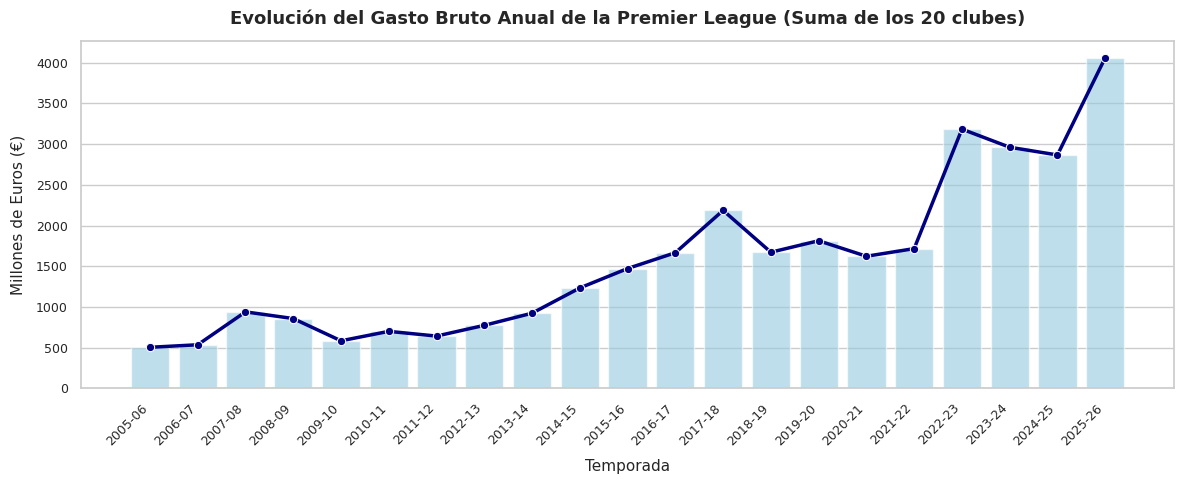

In [47]:
# Configurar el estilo visual
sns.set_theme(style="whitegrid")

# Gráfico 1: Gasto Bruto por Temporada (Ajustado para pantalla y sin etiquetas de texto)
plt.figure(figsize=(12, 5))
sns.barplot(x=gasto_bruto_temporada.index, y=gasto_bruto_temporada.values, color='skyblue', alpha=0.6)
sns.lineplot(x=gasto_bruto_temporada.index, y=gasto_bruto_temporada.values, color='navy', marker='o', linewidth=2.5, markersize=6)

plt.title('Evolución del Gasto Bruto Anual de la Premier League (Suma de los 20 clubes)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Temporada', fontsize=11, labelpad=8)
plt.ylabel('Millones de Euros (€)', fontsize=11, labelpad=8)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)

plt.tight_layout()
plt.show()

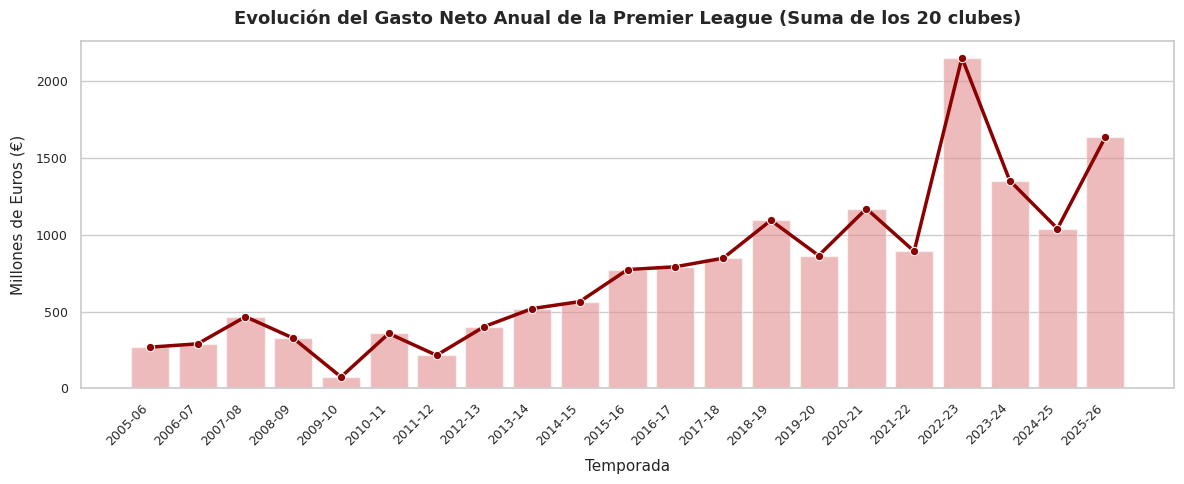

In [48]:
# Configurar el estilo visual
sns.set_theme(style="whitegrid")

# Gráfico 2: Gasto Neto por Temporada (Ajustado para pantalla y sin etiquetas de texto)
plt.figure(figsize=(12, 5))
sns.barplot(x=gasto_neto_temporada.index, y=gasto_neto_temporada.values, color='lightcoral', alpha=0.6)
sns.lineplot(x=gasto_neto_temporada.index, y=gasto_neto_temporada.values, color='darkred', marker='o', linewidth=2.5, markersize=6)

plt.title('Evolución del Gasto Neto Anual de la Premier League (Suma de los 20 clubes)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Temporada', fontsize=11, labelpad=8)
plt.ylabel('Millones de Euros (€)', fontsize=11, labelpad=8)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)

plt.tight_layout()
plt.show()